1. Importación de librerías
Se utilizan PyMongo para conectarse a MongoDB, Pandas para manipular los datos y Matplotlib para las visualizaciones.

In [2]:
from pymongo import MongoClient
import pandas as pd
import matplotlib.pyplot as plt
import re
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)


In [ ]:
%pip install pandas matplotlib pymongo

2. Conexión a MongoDB
La conexión local utiliza mongodb://localhost:27017. Se seleccionan la base taller3_db y la colección raw_data.

In [18]:
MONGO_URI = "mongodb://localhost:27017"
DATABASE_NAME = "taller3_db"
COLLECTION_NAME = "raw_data"

client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=5000)

# Verificar que MongoDB responda
client.admin.command("ping")

db = client[DATABASE_NAME]
collection = db[COLLECTION_NAME]

print("Conexión exitosa a MongoDB")
print("Base de datos:", DATABASE_NAME)
print("Colección:", COLLECTION_NAME)
print("Documentos totales en la colección:", collection.count_documents({}))

Conexión exitosa a MongoDB
Base de datos: taller3_db
Colección: raw_data
Documentos totales en la colección: 121


3. Lectura y selección de variables
La colección contiene distintos recursos de la API. Para este análisis se filtran únicamente los documentos cuyo campo type sea characters. Los atributos del personaje están dentro del campo raw.

Se seleccionan siete variables: nombre, raza, género, Ki, Ki máximo, afiliación y descripción.

In [25]:
documentos = list(collection.find({"resource_type": "characters"}))

print("Personajes encontrados:", len(documentos))

registros = []
for documento in documentos:
    raw = documento.get("raw", {})
    if isinstance(raw, dict):
        registros.append({
            "name": raw.get("name"),
            "race": raw.get("race"),
            "gender": raw.get("gender"),
            "ki": raw.get("ki"),
            "maxKi": raw.get("maxKi"),
            "affiliation": raw.get("affiliation"),
            "description": raw.get("description")
        })

df = pd.DataFrame(registros, columns=[
    "name", "race", "gender", "ki", "maxKi", "affiliation", "description"
])

print("Dimensiones del DataFrame:", df.shape)
display(df.head())

Personajes encontrados: 58
Dimensiones del DataFrame: (58, 7)


,name,race,gender,ki,maxKi,affiliation,description
0,Goku,Saiyan,Male,60.000.000,90 Septillion,Z Fighter,"El protagonista de la serie, conocido por su gran poder y personalidad amigable. Originalmente e..."
1,Vegeta,Saiyan,Male,54.000.000,19.84 Septillion,Z Fighter,"Príncipe de los Saiyans, inicialmente un villano, pero luego se une a los Z Fighters. A pesar de..."
2,Piccolo,Namekian,Male,2.000.000,500.000.000,Z Fighter,"Es un namekiano que surgió tras ser creado en los últimos momentos de vida de su padre, siendo s..."
3,Bulma,Human,Female,0,0,Z Fighter,Bulma es la protagonista femenina de la serie manga Dragon Ball y sus adaptaciones al anime Drag...
4,Freezer,Frieza Race,Male,530.000,52.71 Septillion,Army of Frieza,Freezer es el tirano espacial y el principal antagonista de la saga de Freezer.


4. Limpieza básica
Se eliminan espacios sobrantes en las columnas de texto y se identifican los valores vacíos. No se eliminan personajes por tener Ki desconocido, porque esa información también puede ser relevante para el análisis.

In [26]:
columnas_texto = ["name", "race", "gender", "ki", "maxKi", "affiliation", "description"]

for columna in columnas_texto:
    df[columna] = df[columna].apply(
        lambda valor: valor.strip() if isinstance(valor, str) else valor
    )

# Normalizar cadenas vacías como valores nulos
df[columnas_texto] = df[columnas_texto].replace(r"^\s*$", pd.NA, regex=True)

display(df.head())

,name,race,gender,ki,maxKi,affiliation,description
0,Goku,Saiyan,Male,60.000.000,90 Septillion,Z Fighter,"El protagonista de la serie, conocido por su gran poder y personalidad amigable. Originalmente e..."
1,Vegeta,Saiyan,Male,54.000.000,19.84 Septillion,Z Fighter,"Príncipe de los Saiyans, inicialmente un villano, pero luego se une a los Z Fighters. A pesar de..."
2,Piccolo,Namekian,Male,2.000.000,500.000.000,Z Fighter,"Es un namekiano que surgió tras ser creado en los últimos momentos de vida de su padre, siendo s..."
3,Bulma,Human,Female,0,0,Z Fighter,Bulma es la protagonista femenina de la serie manga Dragon Ball y sus adaptaciones al anime Drag...
4,Freezer,Frieza Race,Male,530.000,52.71 Septillion,Army of Frieza,Freezer es el tirano espacial y el principal antagonista de la saga de Freezer.


5. Análisis exploratorio (EDA)
A. Inspección básica
Se muestran las primeras filas, los tipos de datos y la cantidad de valores nulos por variable.

In [27]:
print("Primeras cinco filas:")
display(df.head())

print("\nInformación general y tipos de datos:")
df.info()

print("\nValores nulos por columna:")
display(df.isnull().sum().to_frame(name="valores_nulos"))

print("\nPorcentaje de valores nulos:")
display((df.isnull().mean() * 100).round(2).to_frame(name="porcentaje_nulos"))

Primeras cinco filas:


,name,race,gender,ki,maxKi,affiliation,description
0,Goku,Saiyan,Male,60.000.000,90 Septillion,Z Fighter,"El protagonista de la serie, conocido por su gran poder y personalidad amigable. Originalmente e..."
1,Vegeta,Saiyan,Male,54.000.000,19.84 Septillion,Z Fighter,"Príncipe de los Saiyans, inicialmente un villano, pero luego se une a los Z Fighters. A pesar de..."
2,Piccolo,Namekian,Male,2.000.000,500.000.000,Z Fighter,"Es un namekiano que surgió tras ser creado en los últimos momentos de vida de su padre, siendo s..."
3,Bulma,Human,Female,0,0,Z Fighter,Bulma es la protagonista femenina de la serie manga Dragon Ball y sus adaptaciones al anime Drag...
4,Freezer,Frieza Race,Male,530.000,52.71 Septillion,Army of Frieza,Freezer es el tirano espacial y el principal antagonista de la saga de Freezer.



Información general y tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   name         58 non-null     str  
 1   race         58 non-null     str  
 2   gender       58 non-null     str  
 3   ki           58 non-null     str  
 4   maxKi        58 non-null     str  
 5   affiliation  58 non-null     str  
 6   description  58 non-null     str  
dtypes: str(7)
memory usage: 3.3 KB

Valores nulos por columna:


,valores_nulos
name,0
race,0
gender,0
ki,0
maxKi,0
affiliation,0
description,0



Porcentaje de valores nulos:


,porcentaje_nulos
name,0.0
race,0.0
gender,0.0
ki,0.0
maxKi,0.0
affiliation,0.0
description,0.0


A.Conversión de Ki a valor numérico
Los campos ki y maxKi llegan como texto. Por ejemplo, pueden contener números con puntos como separadores de miles, expresiones como 90 Septillion o textos como Unknown. La siguiente función convierte los valores reconocibles a números y deja como NaN los valores desconocidos.

Para que el histograma sea legible cuando hay valores muy grandes, se utilizará una escala logarítmica.

In [29]:
def convertir_ki(valor):
    if pd.isna(valor):
        return float("nan")

    texto = str(valor).strip().lower().replace(",", "")
    if texto in {"", "unknown", "n/a", "none", "null", "?"}:
        return float("nan")

    # Sufijos numéricos expresados en inglés
    multiplicadores = {
        "thousand": 1e3,
        "million": 1e6,
        "billion": 1e9,
        "trillion": 1e12,
        "quadrillion": 1e15,
        "quintillion": 1e18,
        "sextillion": 1e21,
        "septillion": 1e24,
        "octillion": 1e27
    }

    for sufijo, factor in multiplicadores.items():
        if sufijo in texto:
            numero = re.search(r"[-+]?[0-9]*\.?[0-9]+", texto)
            return float(numero.group()) * factor if numero else float("nan")

    # Formatos como 60.000.000: se interpretan los puntos como separadores de miles
    if re.fullmatch(r"\d{1,3}(\.\d{3})+", texto):
        return float(texto.replace(".", ""))

    # Formato numérico simple, posiblemente decimal
    try:
        return float(texto.replace(".", "", texto.count(".") - 1) if texto.count(".") > 1 else texto)
    except ValueError:
        return float("nan")

df["ki_numerico"] = df["ki"].apply(convertir_ki)
df["maxKi_numerico"] = df["maxKi"].apply(convertir_ki)

print("Ejemplo de conversión de Ki:")
display(df[["name", "ki", "ki_numerico", "maxKi", "maxKi_numerico"]].head(10))

Ejemplo de conversión de Ki:


,name,ki,ki_numerico,maxKi,maxKi_numerico
0,Goku,60.000.000,60000000.0,90 Septillion,9.000000e+25
1,Vegeta,54.000.000,54000000.0,19.84 Septillion,1.984000e+25
2,Piccolo,2.000.000,2000000.0,500.000.000,5.000000e+08
3,Bulma,0,0.0,0,0.000000e+00
4,Freezer,530.000,530000.0,52.71 Septillion,5.271000e+25
5,Zarbon,20.000,20000.0,30.000,3.000000e+04
6,Dodoria,18.000,18000.0,20.000,2.000000e+04
7,Ginyu,9.000,9000.0,25.000,2.500000e+04
8,Celula,250.000.000,250000000.0,5 Billion,5.000000e+09
9,Gohan,45.000.000,45000000.0,40 septillion,4.000000e+25


B. Cinco insights numéricos
Se calculan cinco resultados que permiten describir la muestra: cantidad de personajes, distribución por género, afiliación más frecuente, raza más frecuente y resumen de los valores de Ki disponibles.

In [30]:
# Insight 1: total de personajes
total_personajes = len(df)
print(f"1. Total de personajes analizados: {total_personajes}")

# Insight 2: distribución por género
genero_conteo = df["gender"].fillna("Sin dato").value_counts()
print("\n2. Personajes por género:")
display(genero_conteo.to_frame(name="cantidad"))

# Insight 3: afiliación más frecuente
afiliacion_conteo = df["affiliation"].fillna("Sin dato").value_counts()
if not afiliacion_conteo.empty:
    afiliacion_top = afiliacion_conteo.index[0]
    cantidad_top = int(afiliacion_conteo.iloc[0])
    porcentaje_top = cantidad_top / total_personajes * 100 if total_personajes else 0
    print(f"\n3. Afiliación más frecuente: {afiliacion_top} "
          f"({cantidad_top} personajes; {porcentaje_top:.2f} %).")

# Insight 4: raza más frecuente
raza_conteo = df["race"].fillna("Sin dato").value_counts()
if not raza_conteo.empty:
    raza_top = raza_conteo.index[0]
    cantidad_raza = int(raza_conteo.iloc[0])
    print(f"\n4. Raza más frecuente: {raza_top} ({cantidad_raza} personajes).")

# Insight 5: resumen de Ki y cantidad de Ki desconocido
ki_validos = df["ki_numerico"].dropna()
ki_desconocidos = int(df["ki_numerico"].isna().sum())

print(f"\n5. Ki desconocido/no convertible: {ki_desconocidos} personajes.")
if not ki_validos.empty:
    print(f"   Promedio de Ki numérico: {ki_validos.mean():,.2f}")
    print(f"   Ki máximo: {ki_validos.max():,.2f}")
    print(f"   Ki mínimo: {ki_validos.min():,.2f}")
else:
    print("   No hay valores de Ki numéricos disponibles.")

1. Total de personajes analizados: 58

2. Personajes por género:


,cantidad
gender,
Male,51
Female,7



3. Afiliación más frecuente: Z Fighter (19 personajes; 32.76 %).

4. Raza más frecuente: Saiyan (10 personajes).

5. Ki desconocido/no convertible: 11 personajes.
   Promedio de Ki numérico: 11,380,853,640,554,267,392,606,208.00
   Ki máximo: 500,000,000,000,000,006,643,777,536.00
   Ki mínimo: 0.00


6. Visualizaciones
Se generan tres gráficos con títulos, etiquetas y formato legible:
1. Torta: proporción de personajes por género.
2. Barras: cantidad de personajes por afiliación.
3. Histograma: distribución del Ki numérico disponible, usando escala logarítmica en el eje horizontal.

In [ ]:
# Gráfico 1: torta de personajes por género
genero_grafico = df["gender"].fillna("Sin dato").value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    genero_grafico.values,
    labels=genero_grafico.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Proporción de personajes por género")
plt.axis("equal")
plt.show()

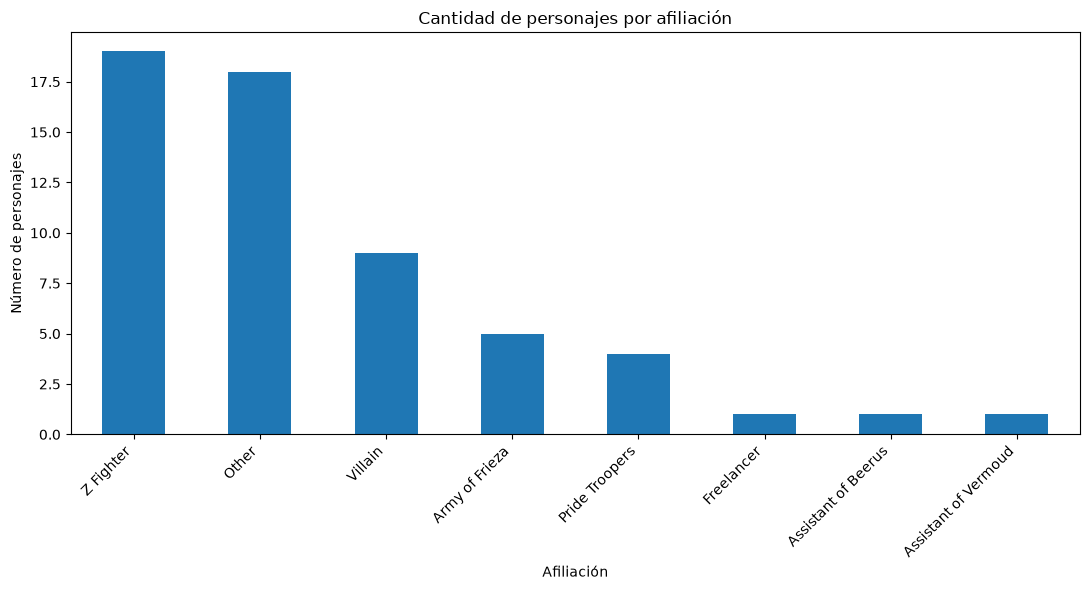

In [34]:
# Gráfico 2: barras de personajes por afiliación
afiliacion_grafico = df["affiliation"].fillna("Sin dato").value_counts()

plt.figure(figsize=(11, 6))
afiliacion_grafico.plot(kind="bar")
plt.title("Cantidad de personajes por afiliación")
plt.xlabel("Afiliación")
plt.ylabel("Número de personajes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

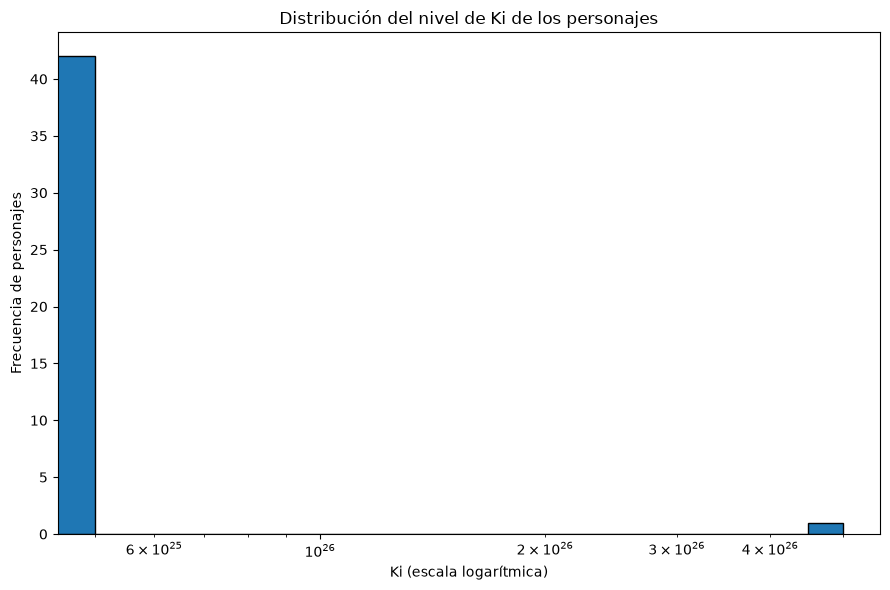

In [35]:
# Gráfico 3: histograma de Ki numérico
ki_grafico = df.loc[df["ki_numerico"] > 0, "ki_numerico"].dropna()

if not ki_grafico.empty:
    plt.figure(figsize=(9, 6))
    plt.hist(ki_grafico, bins=10, edgecolor="black")
    plt.xscale("log")
    plt.title("Distribución del nivel de Ki de los personajes")
    plt.xlabel("Ki (escala logarítmica)")
    plt.ylabel("Frecuencia de personajes")
    plt.tight_layout()
    plt.show()
else:
    print("No hay valores positivos de Ki para construir el histograma.")

7. Conclusión
Completa esta conclusión después de ejecutar todas las celdas y revisar los resultados:

El análisis exploratorio permitió estudiar la distribución de los personajes de Dragon Ball según su género, raza y afiliación, además de examinar los niveles de Ki disponibles. La afiliación con mayor cantidad de personajes fue [Z Fighter (19 personajes; 32.76 %)]. La raza más frecuente fue [Saiyan (10 personajes)]. Se identificaron [ 11 ] personajes con Ki desconocido o no convertible. En conjunto, las tablas y gráficos permiten reconocer las categorías predominantes y las características generales de los personajes consultados desde MongoDB.

8. Cierre de conexión
Ejecuta esta celda al terminar el análisis para cerrar la conexión con MongoDB.

In [ ]:
client.close()
print("Conexión con MongoDB cerrada.")